In [1]:
import matplotlib.pyplot as plt
import numpy as np
import astropy.io.ascii as ascii

from scipy.stats import binned_statistic

from tqdm import tqdm

from scipy.stats import norm

import matplotlib.lines as mlines

from astropy.table import vstack

In [28]:
ROMAN = ascii.read("../sims/ROMAN/FITOPT000_ROMAN.FITRES")
ROMAN_max = ascii.read("../sims/ROMAN/FITOPT000_ROMAN_EBV_IGM_MAX.FITRES")
ROMAN_med = ascii.read("../sims/ROMAN/FITOPT000_ROMAN_EBV_IGM_MED.FITRES")

In [3]:
DES = ascii.read("../sims/DES/FITOPT000_DES_NEW_P21.FITRES")
DES_max = ascii.read("../sims/DES/FITOPT000_DES_NEW_P21_EBV_IGM_MAX.FITRES")

In [14]:
LSST_highz = ascii.read("../sims/LSST/HIGHZ/DDF_FITOPT000_BBC_LSST_HIGHZ.FITRES")

In [15]:
LSST_highz_max = ascii.read("../sims/LSST/HIGHZ/DDF_FITOPT000_BBC_LSST_HIGHZ_EBV_IGM_MAX.FITRES")

In [16]:
LSST_highz_med = ascii.read("../sims/LSST/HIGHZ/DDF_FITOPT000_BBC_LSST_HIGHZ_EBV_IGM_MED.FITRES")

In [13]:
LSST_lowz = ascii.read("../sims/LSST/LOWZ/FITOPT000_BBC_LSST_LOWZ.FITRES")
LSST_lowz_max = ascii.read("../sims/LSST/LOWZ/FITOPT000_BBC_LSST_LOWZ_EBV_IGM_MAX.FITRES")
LSST_lowz_med = ascii.read("../sims/LSST/LOWZ/FITOPT000_BBC_LSST_LOWZ_EBV_IGM_MED.FITRES")

In [19]:
LSST = vstack([LSST_lowz,LSST_highz])
LSST_max = vstack([LSST_lowz_max,LSST_highz_max])
LSST_med = vstack([LSST_lowz_med,LSST_highz_med])

In [9]:
def create_filt(file):
    
    filt = (np.abs(file['c']) < 0.3) & (np.abs(file['x1']) < 3) & (file['x1ERR'] < 1) & (file['PKMJDERR'] < 2) & (file['FITPROB'] > 0.001) & (file['SIM_AV'] > -9)
    
    return filt

In [10]:
def bin_vals(x,y,num_bins=30):
    bin_edges = np.linspace(np.min(x),np.max(x),num_bins+1)
    
    bin_means, _, _ = binned_statistic(x,y,statistic='median',bins=bin_edges)
    bin_std, _, _ = binned_statistic(x,y,statistic='std',bins=bin_edges)
    bin_count, _, _ = binned_statistic(x,y,statistic='count',bins=bin_edges)
    
    bin_std_errors = bin_std/np.sqrt(bin_count)
    
    return bin_edges, bin_means, bin_std_errors

In [51]:
def plot_mu_dif(nodust,dust,label="",color="",alpha=1):
    mures = nodust['mB']+0.14*nodust['x1']-3.1*nodust['c']+19.35-nodust['SIM_DLMAG']
    corr_mures = dust['mB']+0.14*dust['x1']-3.1*dust['c']+19.35-dust['SIM_DLMAG']

    bin_edges1, mu_bin_means1, mu_bin_std1 = bin_vals(nodust['zHD'],mures)
    bin_edges2, mu_bin_means2, mu_bin_std2 = bin_vals(dust['zHD'],corr_mures)

#     plt.errorbar((bin_edges1[:-1] + bin_edges1[1:]) / 2, mu_bin_means1,yerr=mu_bin_std1,
#                  ls = 'none',marker='s', c='C3', label='nodust')
#     plt.errorbar((bin_edges2[:-1] + bin_edges2[1:]) / 2, mu_bin_means2,yerr=mu_bin_std2,
#                  ls = 'none',marker='s', c='C4', label='dust')

#     plt.ylabel("$\mu_\mathrm{res}$ (mag)",fontsize=14)
#     plt.xlabel("$z$",fontsize=14)
#     plt.legend()

#     plt.show()
    
#     plt.figure(figsize=(6,4.5))
    plt.scatter((bin_edges1[:-1] + bin_edges1[1:]) / 2,mu_bin_means2-mu_bin_means1,label=label,zorder=20,color=color,alpha=alpha)
    plt.errorbar((bin_edges1[:-1] + bin_edges1[1:]) / 2,mu_bin_means2-mu_bin_means1,
                 yerr=np.sqrt(mu_bin_std1**2+mu_bin_std2**2),
                 ls = 'none',alpha=0.8*alpha,fmt='none',c='k',elinewidth=0.5,zorder=2)
    # plt.scatter((bin_edges1[:-1] + bin_edges1[1:]) / 2,1*(bin_means3-bin_means1),label="BS20_corr - BS20")
    plt.xlabel("$z$",fontsize=14)
    plt.ylabel("$\Delta\mu$ (mag)",fontsize=14)
    plt.legend(fontsize=14,loc='upper left')
    plt.axhline(c='k',ls='--',zorder=1)
#     plt.ylim(-0.005,0.03)
    # plt.savefig("pdfs/mu_from_igdust.pdf",bbox_inches='tight')
    # plt.savefig("pngs/mu_from_igdust.png",bbox_inches='tight')
#     plt.show()

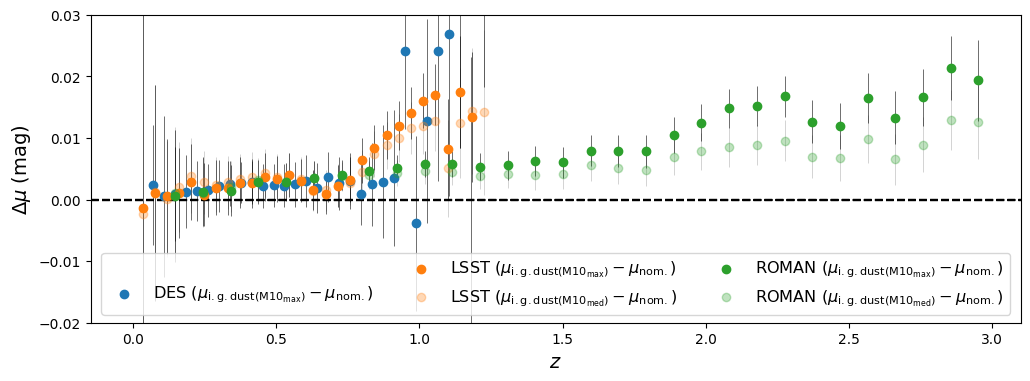

In [52]:
plt.figure(figsize=(12,4))
plt.scatter(0,0,c="white",label=" ")
plot_mu_dif(DES[create_filt(DES)&(np.isin(DES['FIELD'],['X3','C3']))],DES_max[create_filt(DES_max)&(np.isin(DES_max['FIELD'],['X3','C3']))],label="DES ($\mu_\mathrm{i.g.dust(M10_{max})} - \mu_\mathrm{nom.}$)",color="C0")
plot_mu_dif(LSST[create_filt(LSST)&(np.isin(LSST['FIELD'],['DDF']))],LSST_max[create_filt(LSST_max)&(np.isin(LSST_max['FIELD'],['DDF']))],label="LSST ($\mu_\mathrm{i.g.dust(M10_{max})} - \mu_\mathrm{nom.}$)",color="C1")
plot_mu_dif(LSST[create_filt(LSST)&(np.isin(LSST['FIELD'],['DDF']))],LSST_med[create_filt(LSST_med)&(np.isin(LSST_med['FIELD'],['DDF']))],label="LSST ($\mu_\mathrm{i.g.dust(M10_{med})} - \mu_\mathrm{nom.}$)",color="C1",alpha=0.3)
plot_mu_dif(ROMAN[create_filt(ROMAN)&(np.isin(ROMAN['FIELD'],['DEEP']))],ROMAN_max[create_filt(ROMAN_max)&(np.isin(ROMAN_max['FIELD'],['DEEP']))],label="ROMAN ($\mu_\mathrm{i.g.dust(M10_{max})} - \mu_\mathrm{nom.}$)",color="C2")
plot_mu_dif(ROMAN[create_filt(ROMAN)&(np.isin(ROMAN['FIELD'],['DEEP']))],ROMAN_med[create_filt(ROMAN_med)&(np.isin(ROMAN_med['FIELD'],['DEEP']))],label="ROMAN ($\mu_\mathrm{i.g.dust(M10_{med})} - \mu_\mathrm{nom.}$)",color="C2",alpha=0.3)
plt.ylim(-0.02,0.03)
plt.legend(loc="lower center",ncol=3,fontsize=11.6)
plt.savefig("pdfs/combined_mu_dif.pdf",bbox_inches='tight')
plt.show()